In [1]:
import bohnasa
import matplotlib.pyplot as plt 
import numpy as np


In [1]:
N = 1000
L = 2
fock = bohnasa.fockStates_fixed_particle_number(N,L)

f = np.zeros(L)
f[0] = N


sta1 = bohnasa.single_fockstate(fock, f)
f = np.zeros(L)
f[-1] = N
sta2 = bohnasa.single_fockstate(fock, f)


sta = np.random.rand(fock.dim) #sta1 #+sta2
sta *= 1/np.linalg.norm(sta)
phi = np.full(L,1j,dtype=complex)*(-1)**np.arange(L)
#phi = np.random.rand(L)-0.5 + 1j*(np.random.rand(L)-0.5)
sta = bohnasa.coherent_state_number_projected(fock,phi)
print(sta,np.linalg.norm(sta))
hopping = bohnasa.hopping(fock)
hopping.matrix *= -1
interaction = bohnasa.interaction(fock)
interaction.matrix *= 4
test_op = hopping + interaction

def gs(X, row_vecs=True, norm = True):
    if not row_vecs:
        X = X.T
    Y = X[0:1,:].copy()
    print(X.shape)
    for i in range(1, X.shape[0]):
        proj = np.diag((X[i,:].dot(Y.T)/np.linalg.norm(Y,axis=1)**2).flat).dot(Y)
        newT = X[i,:] - proj.sum(0)
        newT *= 1/np.linalg.norm(newT)
        print("newT",newT)
        Y = np.vstack((Y, newT))
        
    if norm:
        Y = np.diag(1/np.linalg.norm(Y,axis=1)).dot(Y)
    if row_vecs:
        return Y
    else:
        return Y.T
"""
def lanzos(sta,op,krylov_dim,beta_tol=1e-8):

    v = np.zeros((krylov_dim + 1, sta.shape[0]), dtype=complex)
    T_m = np.zeros((krylov_dim+1,krylov_dim+1),dtype=complex)
    v[0] = sta/np.linalg.norm(sta)

    w_prime = op(v[0])

    alpha = np.vdot(w_prime, v[0, :])

    w = w_prime - alpha * v[0, :]

    T_m[0, 0] = alpha

    for j in range(1, krylov_dim + 1):

        beta = np.linalg.norm(w)

        if beta < beta_tol:

            # Happy breakdown
            v_happy = v[0:j, :]
            T_m_happy = T_m[0:j, 0:j]

            return v_happy, T_m_happy

        v[j, :] = w / beta
        w_prime = op(v[j, :])
        alpha = np.vdot(w_prime, v[j, :])

        w = w_prime - alpha * v[j, :] - beta * v[j - 1, :]

        T_m[j, j] = alpha
        T_m[j, j - 1] = beta
        T_m[j - 1, j] = beta

    return v, T_m

"""

NameError: name 'bohnasa' is not defined

In [2]:
numbVec = fock.dim-1
v, T_m = bohnasa.lanczos(sta,test_op,numbVec,1e-5)

np.linalg.norm(v,axis=1),v.shape


np.isclose(np.eye(N=v.shape[0]),(v@v.T)).all()


NameError: name 'fock' is not defined

In [14]:
print(v,v.shape)

[[ 8.06326514e-03+0.j  3.67832333e-02+0.j  4.62465272e-02+0.j ...
   4.22273410e-02+0.j  3.86260532e-02+0.j  1.73940350e-02+0.j]
 [ 2.91287039e-02+0.j  1.24105498e-01+0.j  1.43779799e-01+0.j ...
   1.42834726e-01+0.j  1.31157770e-01+0.j  6.33821534e-02+0.j]
 [ 4.80010440e-02+0.j  1.80076190e-01+0.j  1.76938040e-01+0.j ...
   2.08147614e-01+0.j  1.92437915e-01+0.j  1.05965786e-01+0.j]
 ...
 [ 1.06044766e-18+0.j -7.25173507e-19+0.j  1.11503721e-17+0.j ...
  -3.68093027e-18+0.j  2.04975895e-18+0.j -1.00150119e-17+0.j]
 [ 5.86023210e-18+0.j  6.27844009e-19+0.j -2.94374486e-18+0.j ...
  -1.82365575e-18+0.j  1.20413904e-17+0.j  8.99823792e-18+0.j]
 [-1.80506260e-17+0.j  1.76615639e-17+0.j -2.54876880e-18+0.j ...
  -2.90778455e-17+0.j -3.11028561e-18+0.j -3.46277098e-19+0.j]] (1326, 1326)


np.True_

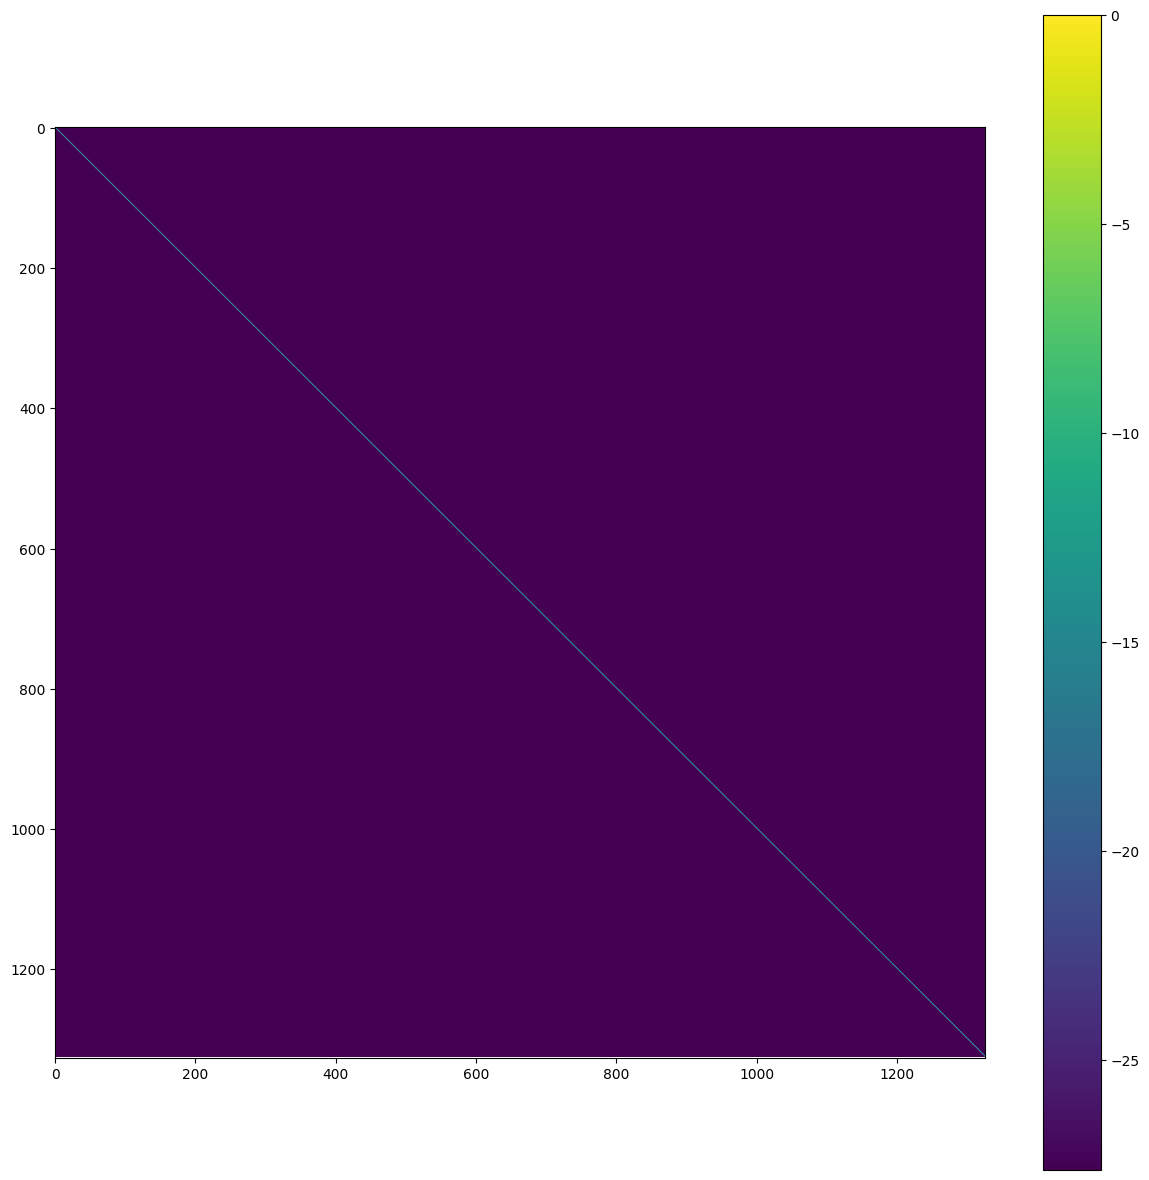

In [15]:
plt.figure(figsize=(15,15))
#plt.imshow(np.log(v@v.T).real)
plt.imshow(np.log(v@v.T +1e-12).real)
##plt.imshow(T_m.real,vmin=-3)
plt.colorbar()

np.isclose(np.eye(N=v.shape[0]),(v@v.T)).all()


In [16]:
time = np.linspace(0,20,100)
ob = [test_op,bohnasa.number(fock,0),bohnasa.Krylov_complexity(fock,test_op,sta,numbVec)]

In [17]:

res = bohnasa.time_evolution_exact_ind(test_op,sta,time,ob)

(1326,)
(1326,)


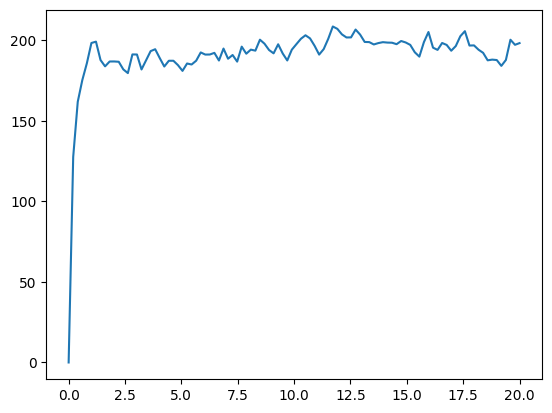

In [18]:
plt.plot(time,res[2,0])


(0.001, np.float64(1299.8209721414264))

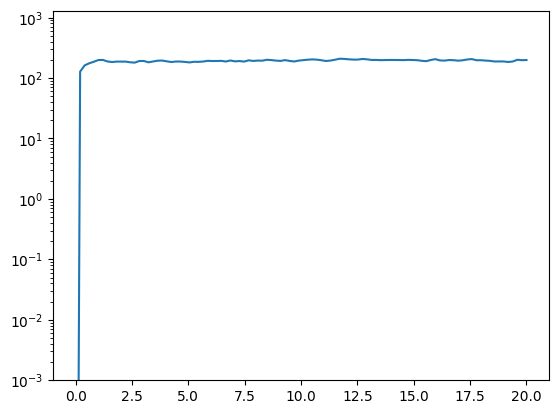

In [19]:
plt.semilogy(time,res[2,0])
plt.ylim(1e-3,None)

(0.0, 10.0)

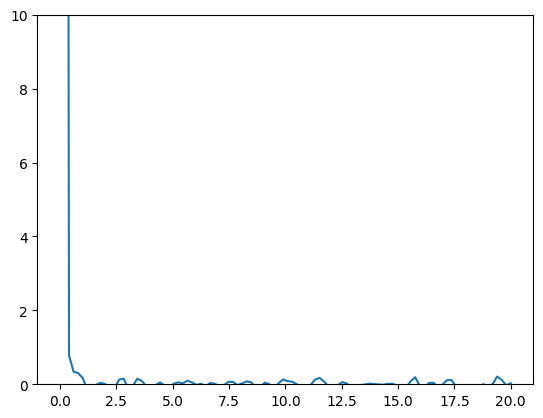

In [20]:
plt.plot(time,np.gradient(np.log(res[2,0]),time))
plt.ylim(0,10)

In [11]:
sta

array([1.29643656e-02, 5.55315264e-02, 2.89354288e-02, 2.58472946e-02,
       4.64018394e-02, 1.46104221e-03, 6.97154131e-02, 3.65330101e-02,
       6.89521504e-02, 5.50563461e-02, 5.34949705e-02, 2.16690691e-02,
       7.70363163e-02, 5.62846619e-02, 5.89727240e-02, 9.69214773e-03,
       6.13040452e-02, 7.36114322e-02, 6.66821170e-02, 4.55945552e-02,
       8.75879537e-03, 6.53968086e-02, 5.82919149e-02, 4.79277469e-02,
       1.71764048e-02, 2.45148102e-02, 7.82673202e-02, 6.84711657e-02,
       3.99436447e-02, 4.19699661e-02, 7.68337269e-02, 4.54180408e-02,
       4.43693429e-03, 2.34617512e-02, 1.92824707e-02, 5.37964414e-02,
       2.64334045e-03, 2.93862277e-02, 7.59885758e-03, 6.43573202e-02,
       7.20489263e-04, 3.67693883e-02, 2.03576386e-02, 1.46445392e-02,
       3.92752086e-02, 6.15147286e-02, 2.03365874e-02, 4.06645742e-02,
       5.17762251e-02, 2.65424242e-03, 5.37918941e-02, 6.97148599e-02,
       3.16962271e-02, 4.88370221e-02, 5.05488980e-02, 1.84368659e-02,
      